# UpShift — finding jobs and explaining skill gaps

**Aim:** help a student find relevant early-career roles and see which required skills their profile does not mention.

Run this notebook from top to bottom. Everything needed for the experiment is here: **data understanding → cleaning → EDA → modelling → evaluation → a working example → saving and an AI-service interface**. The three original CSVs are the inputs; no separate project code files are needed.

We use **NLP**, which means processing written language. TF-IDF compares important words; semantic matching compares meaning. Logistic regression is a learning algorithm. Sentiment analysis is a separate task: deciding whether feedback sounds positive, neutral or negative.

## 1. Set up and load the data

In Colab, connect Drive and choose the folder containing the three CSVs. The two project folder names used so far are checked automatically. On this PC, the original Downloads files are used. Outputs go in a new `UpShift_clear_steps` folder.

The first run needs internet for the English sentiment dataset and the pretrained meaning model. Neither sends our CVs to an online prediction service. CPU work is limited to two threads.

In [1]:
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'scikit-learn==1.7.2', 'nltk==3.9.2',
                    'sentence-transformers==5.1.2', 'transformers==4.57.1',
                    'fastapi==0.121.0', 'httpx==0.28.1', 'uvicorn==0.38.0'], check=True)
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'
os.environ['HF_HUB_DISABLE_XET'] = '1'

In [2]:
import re, html, json, hashlib, time, unicodedata, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from collections import Counter
from IPython.display import display
from threadpoolctl import threadpool_limits

SEED = 42
thread_limit = threadpool_limits(limits=2)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_colwidth', 70)
BLUE, ORANGE = '#3158E8', '#D98432'

In [3]:
if IN_COLAB:
    folders = [Path('/content/drive/MyDrive/UpShift_AI_Data'),
               Path('/content/drive/MyDrive/INTERNSHIP_MATCH PROJECT/AI Datasets/AI Datasets')]
    DATA = next((p for p in folders if (p / 'Resume.csv').exists()), folders[0])
    resume_path, jobs_path, skills_path = [DATA / n for n in
                                          ['Resume.csv', 'postings.csv', 'skills_en.csv']]
    OUT = DATA / 'UpShift_clear_steps'
else:
    DATA = Path.home() / 'Downloads'
    resume_path = DATA / 'archive/Resume/Resume.csv'
    jobs_path, skills_path = DATA / 'postings.csv', DATA / 'skills_en.csv'
    OUT = Path.cwd() / 'clear_results'

for p in [resume_path, jobs_path, skills_path]:
    if not p.is_file(): raise FileNotFoundError(f'Choose the correct data folder: {p}')
OUT.mkdir(parents=True, exist_ok=True)
print('Results folder:', OUT)

Results folder: C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\ai\clear_results


### 1.1 What each dataset gives us

- **Resumes:** CV text and a known career category. The category is useful for testing a classifier.
- **Postings:** job descriptions and practical details such as location, dates and application links.
- **ESCO:** standard skill names and other spellings of the same skills.

We load only the columns used here. Salary, views and application counts are not model inputs, so they do not need scaling for these text models.

In [4]:
resumes_raw = pd.read_csv(resume_path, usecols=['ID', 'Resume_str', 'Category'], dtype=str)
job_columns = ['job_id', 'title', 'description', 'company_name', 'location',
               'remote_allowed', 'formatted_work_type', 'formatted_experience_level',
               'listed_time', 'expiry', 'closed_time', 'application_url',
               'job_posting_url', 'skills_desc']
jobs_raw = pd.read_csv(jobs_path, usecols=job_columns, dtype={'job_id': str}, low_memory=False)
skills_raw = pd.read_csv(skills_path, dtype=str)

display(pd.DataFrame({'Dataset': ['Resumes', 'Job postings', 'ESCO skills'],
                      'Rows': [len(resumes_raw), len(jobs_raw), len(skills_raw)]}))
display(resumes_raw[['ID', 'Category']].head(3))
display(jobs_raw[['title', 'location', 'formatted_experience_level']].head(3))

,Dataset,Rows
0,Resumes,2484
1,Job postings,123849
2,ESCO skills,13960


,ID,Category
0,16852973,HR
1,22323967,HR
2,33176873,HR


,title,location,formatted_experience_level
0,Marketing Coordinator,"Princeton, NJ",NaN
1,Mental Health Therapist/Counselor,"Fort Collins, CO",NaN
2,Assitant Restaurant Manager,"Cincinnati, OH",NaN


## 2. Data cleaning

First check missing text and duplicates. We remove unusable text, rather than inventing it. Missing company names or salaries do not mean that a job description must be deleted.

In [5]:
checks = pd.DataFrame({
    'Check': ['Blank CV text', 'Repeated CV text', 'Blank job descriptions',
              'Repeated job IDs', 'Repeated ESCO IDs'],
    'Rows': [resumes_raw.Resume_str.fillna('').str.strip().eq('').sum(),
             resumes_raw.Resume_str.duplicated().sum(),
             jobs_raw.description.fillna('').str.strip().eq('').sum(),
             jobs_raw.job_id.duplicated().sum(), skills_raw.conceptUri.duplicated().sum()]})
display(checks)
display((jobs_raw[['description', 'skills_desc', 'location', 'expiry']]
         .isna().mean().mul(100).round(1).rename('Missing (%)').to_frame()))

,Check,Rows
0,Blank CV text,1
1,Repeated CV text,2
2,Blank job descriptions,7
3,Repeated job IDs,0
4,Repeated ESCO IDs,21


,Missing (%)
description,0.0
skills_desc,98.0
location,0.0
expiry,0.0


### 2.1 Use one text-cleaning rule

Remove HTML, links and email addresses, use lowercase and reduce extra spaces. Keep punctuation that belongs to a technology name: **C++, C#, .NET and Node.js**. Long documents stay; their length alone does not make them wrong.

In [6]:
TOKEN_PATTERN = r"(?u)(?:\.net\b|\b\w+(?:[.+#-]\w+)*(?:\+\+|#)?)"

def plain_text(text):
    if not isinstance(text, str): return ''
    text = html.unescape(unicodedata.normalize('NFKC', text))
    text = re.sub(r'<[^>]+>', ' ', text)
    return text.replace('\r\n', '\n').replace('\r', '\n').strip()

def clean_text(text):
    text = plain_text(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+|\S+@\S+', ' ', text)
    text = re.sub(r'[^\w+#.\s-]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

print(clean_text('My projects use C++, C#, .NET and Node.js.'))

my projects use c++ c# .net and node.js.


### 2.2 Clean resumes and remove the opening title

A title such as “HR ADMINISTRATOR” can give away the category. Remove up to two short capital-letter title lines, but keep section headings such as “Skills”. Also remove the dataset's generic “Company Name” and “City, State” placeholders. The same preparation is used when someone enters a new CV.

In [7]:
SECTION_WORDS = {'summary', 'skills', 'experience', 'education', 'objective',
                 'profile', 'highlights', 'qualifications', 'career', 'professional'}

def prepare_resume(text):
    text = plain_text(text)
    for _ in range(2):
        parts = re.split(r'\s{2,}|\n', text, maxsplit=1)
        line = parts[0]
        letters = [c for c in line if c.isalpha()]
        first = (re.findall(r'[a-z]+', line.lower()) or [''])[0]
        is_title = (len(parts) == 2 and 0 < len(line) <= 80 and letters
                    and sum(c.isupper() for c in letters) / len(letters) > .8
                    and first not in SECTION_WORDS)
        if not is_title: break
        text = parts[1].lstrip()
    text = re.sub(r'\bcompany name\b|\bcity\s*,?\s*state\b', ' ', text, flags=re.I)
    return clean_text(text)

In [8]:
resumes = resumes_raw.fillna('').copy()
resumes['text'] = resumes.Resume_str.map(prepare_resume)
conflicts = resumes.groupby('text').Category.nunique()
bad_text = set(conflicts[conflicts > 1].index)
resumes = resumes[resumes.text.ne('') & ~resumes.text.isin(bad_text)]
resumes = resumes.drop_duplicates('text').reset_index(drop=True)
resumes['words'] = resumes.text.str.split().str.len()

print('CVs before:', len(resumes_raw), '| after:', len(resumes))
print('Conflicting duplicate texts removed:', len(bad_text))
print('Before:', resumes.Resume_str.iloc[0][:160])
print('After: ', resumes.text.iloc[0][:160])

CVs before: 2484 | after: 2481
Conflicting duplicate texts removed: 0
Before:          HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality
After:  summary dedicated customer service manager with 15+ years of experience in hospitality and customer service management. respected builder and leader of customer


### 2.3 Clean postings and retain useful job details

Keep postings with a title and description. Select internships and entry-level roles. Dates, location and links stay because users need them. “Entry level” does **not** establish Kenyan eligibility or prove that a vacancy is still open.

In [9]:
jobs = jobs_raw.fillna('').drop_duplicates('job_id').copy()
jobs = jobs[jobs.title.str.strip().ne('') & jobs.description.str.strip().ne('')]
jobs['is_internship'] = (jobs.formatted_work_type.str.upper().eq('INTERNSHIP')
                         | jobs.formatted_experience_level.str.lower().eq('internship'))
jobs['entry'] = jobs.formatted_experience_level.str.lower().eq('entry level')
jobs = jobs[jobs.is_internship | jobs.entry].copy()
jobs['description'] = jobs.description.map(plain_text)
jobs['text'] = (jobs.title + '\n' + jobs.description + '\n' + jobs.skills_desc).map(clean_text)
jobs = jobs.drop_duplicates(['title', 'company_name', 'text'])
print('Unique early-career postings:', len(jobs))

Unique early-career postings: 33412


### 2.4 Label obvious job fields for a limited check

Postings have no reliable career-category labels. These title rules give a rough field label only when exactly one field matches. For example, “accountant” suggests accounting. This is a **rough category check**, not a human judgement that a particular student is suitable.

In [10]:
TITLE_RULES = {'INFORMATION-TECHNOLOGY': '\\b(?:software|developer|network|help desk|it support|system administrator|data scientist|data analyst)\\b',
    'ACCOUNTANT': '\\b(?:accountant|accounting|bookkeeper)\\b',
    'BANKING': '\\b(?:bank|banking|teller)\\b',
    'CHEF': '\\b(?:chef|cook|kitchen)\\b',
    'CONSTRUCTION': '\\b(?:construction|carpenter|electrician|plumber)\\b',
    'ENGINEERING': '\\bengineer\\b',
    'FINANCE': '\\b(?:finance|financial)\\b',
    'FITNESS': '\\b(?:fitness|personal trainer)\\b',
    'HEALTHCARE': '\\b(?:nurse|medical|patient care|clinical|pharmacist)\\b',
    'HR': '\\b(?:hr|human resources|recruiter|recruitment)\\b',
    'SALES': '\\bsales\\b',
    'TEACHER': '\\b(?:teacher|tutor|instructor)\\b',
    'DESIGNER': '\\b(?:designer|design intern)\\b',
    'DIGITAL-MEDIA': '\\b(?:digital marketing|social media|content creator)\\b'}


def title_category(title):
    hits = [name for name, pattern in TITLE_RULES.items()
            if re.search(pattern, clean_text(title))]
    return hits[0] if len(hits) == 1 else None

jobs['field'] = jobs.title.map(title_category)

### 2.5 Use a manageable, repeatable catalogue

Use 6,000 postings so the experiment runs on a student computer. Reserve up to 100 per recognisable field, then fill the remaining places randomly. Both matching methods will use this same catalogue. It is a research sample, not a representative count of today's labour market.

In [11]:
MAX_JOBS = 6000
if len(jobs) > MAX_JOBS:
    reserved = (jobs[jobs.field.notna()].sample(frac=1, random_state=SEED)
                .groupby('field').head(100))
    remainder = jobs.drop(index=reserved.index)
    rng = np.random.default_rng(SEED)
    extra = rng.choice(remainder.index, MAX_JOBS - len(reserved), replace=False)
    jobs = pd.concat([reserved, remainder.loc[extra]])
jobs = jobs.sort_values('job_id', kind='stable').reset_index(drop=True)
for column in ['listed_time', 'expiry']:
    jobs[column + '_date'] = pd.to_datetime(pd.to_numeric(jobs[column], errors='coerce'),
                                           unit='ms', utc=True, errors='coerce')
jobs['expired'] = jobs.expiry_date.notna() & (jobs.expiry_date < pd.Timestamp.now(tz='UTC'))
jobs['eligibility'] = 'unverified'
print('Indexed:', len(jobs), '| expired:', jobs.expired.sum())

Indexed: 6000 | expired: 6000


### 2.6 Clean ESCO and save the cleaned tables

An ESCO identifier refers to one skill, even if that skill has several names. Remove repeated identifiers and blank names. Keep missing synonyms as empty text. These cleaned tables are saved for inspection; we still keep the original files.

In [12]:
skills = skills_raw.fillna('').drop_duplicates('conceptUri').copy()
skills = skills[skills.conceptUri.ne('') & skills.preferredLabel.str.strip().ne('')]
skills['name_words'] = skills.preferredLabel.str.split().str.len()
resumes.to_csv(OUT / 'resume_clean.csv', index=False)
jobs.to_csv(OUT / 'jobs_clean.csv', index=False)
skills.to_csv(OUT / 'skills_clean.csv', index=False)
display(pd.DataFrame({'Dataset': ['Resumes', 'Early-career job sample', 'ESCO skills'],
                      'Clean rows': [len(resumes), len(jobs), len(skills)]}))

,Dataset,Clean rows
0,Resumes,2481
1,Early-career job sample,6000
2,ESCO skills,13939


## 3. Exploratory data analysis (EDA)

Before modelling, ask: are CV categories balanced, how long are the texts, what jobs are present, and does the skills list describe short words or longer phrases? The plots answer those questions; we do not add charts for variables the models never use.

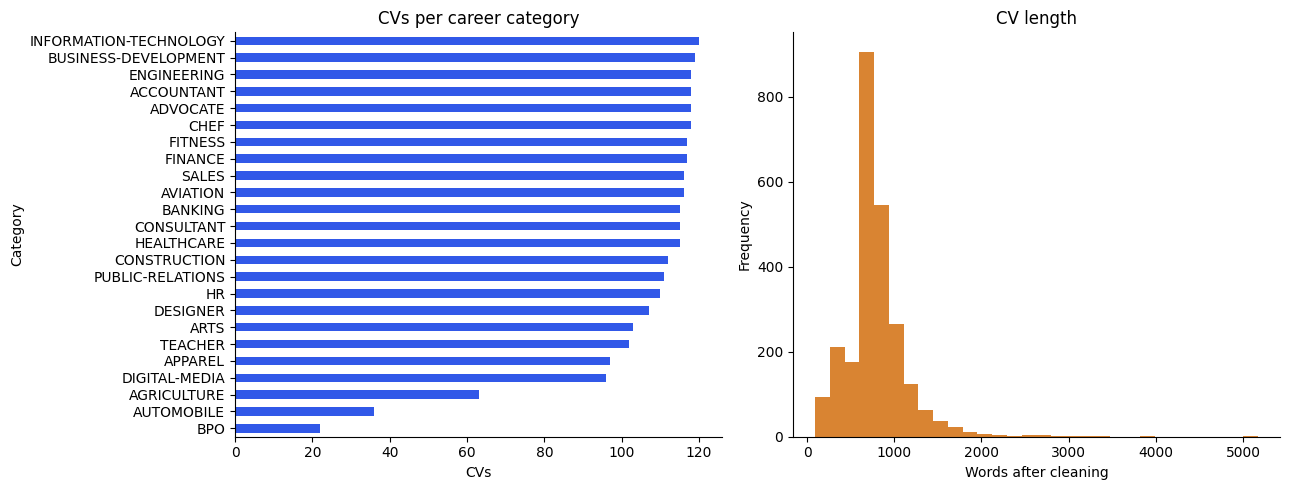

Smallest category: BPO 22
Largest category: INFORMATION-TECHNOLOGY 120
Median CV length: 733 words


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
counts = resumes.Category.value_counts().sort_values()
counts.plot.barh(ax=axes[0], color=BLUE, title='CVs per career category')
axes[0].set_xlabel('CVs')
resumes.words.plot.hist(ax=axes[1], bins=30, color=ORANGE, title='CV length')
axes[1].set_xlabel('Words after cleaning')
fig.tight_layout()
plt.show()
print('Smallest category:', counts.idxmin(), int(counts.min()))
print('Largest category:', counts.idxmax(), int(counts.max()))
print('Median CV length:', int(resumes.words.median()), 'words')

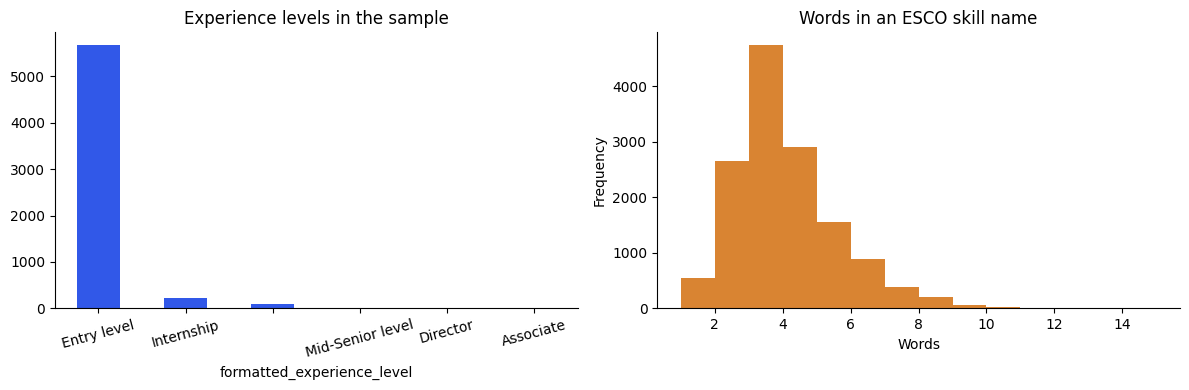

,Postings
location,
United States,216
"New York, NY",104
"Chicago, IL",77
"Houston, TX",70
"Atlanta, GA",62


Expired postings: 6000 of 6000


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
jobs.formatted_experience_level.value_counts().plot.bar(
    ax=axes[0], color=BLUE, title='Experience levels in the sample', rot=15)
skills.name_words.plot.hist(ax=axes[1], bins=range(1, 16), color=ORANGE,
                            title='Words in an ESCO skill name')
axes[1].set_xlabel('Words')
fig.tight_layout()
plt.show()
display(jobs.location.value_counts().head(5).rename('Postings').to_frame())
print('Expired postings:', int(jobs.expired.sum()), 'of', len(jobs))

### What the EDA means for the model

Use a split that preserves the share of each CV category. Report **macro F1**, which gives each category equal weight, alongside accuracy. Keep long CVs, but acknowledge that the meaning model reads sampled sections. Search whole skill phrases rather than single words only. An internship tag can conflict with a senior experience label; we keep the source labels visible rather than calling eligibility verified. Location and expiry limit what we can claim about Kenyan opportunities. The datasets also do not establish that the CVs represent Kenyan students.

## 4. Modelling

There are three separate questions:

| Question | Method | Role in UpShift |
|---|---|---|
| What career field does a CV resemble? | CV-category classifiers | Supporting experiment |
| Which jobs resemble the CV? | TF-IDF and semantic matching | Main recommendation task |
| How does feedback sound? | VADER and logistic regression | Separate sentiment task |

The career classifier does not filter jobs, and sentiment never scores a person's employability.

### 4.1 Split the resumes before learning words

Keep 20% aside for the final test. Learn vocabulary from training CVs only. The same split is used by every career classifier. Three practice rounds on the training portion are used to choose the classifier; test results are checked afterwards.

In [15]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics.pairwise import cosine_similarity

train_ids, test_ids = train_test_split(resumes.index, test_size=.2,
                                      stratify=resumes.Category, random_state=SEED)
x_train, x_test = resumes.loc[train_ids, 'text'], resumes.loc[test_ids, 'text']
y_train, y_test = resumes.loc[train_ids, 'Category'], resumes.loc[test_ids, 'Category']
cv = StratifiedKFold(3, shuffle=True, random_state=SEED)
print('Training CVs:', len(train_ids), '| test CVs:', len(test_ids))

Training CVs: 1984 | test CVs: 497


### 4.2 Train and compare career classifiers

TF-IDF turns important words and two-word phrases into numbers. Logistic regression, SVM and Naive Bayes learn from those numbers. The baseline always guesses the most common category.

Use fixed settings to keep this comparison short. Training-only cross-validation chooses between these candidates; this is not an exhaustive search for the best settings. Check the held-out results only afterwards.

In [16]:
def text_pipeline(model):
    words = TfidfVectorizer(token_pattern=TOKEN_PATTERN, ngram_range=(1, 2),
                            min_df=2, max_df=.95, max_features=30000, sublinear_tf=True)
    return Pipeline([('words', words), ('model', model)])

career_models = {
    'Logistic regression': LogisticRegression(C=10, class_weight='balanced', max_iter=2000, random_state=SEED),
    'Linear SVM': LinearSVC(C=10, max_iter=5000, random_state=SEED),
    'Naive Bayes': ComplementNB(alpha=.1),
    'Majority baseline': DummyClassifier(strategy='most_frequent')}

fitted_career, practice = {}, []
for name, model in career_models.items():
    pipeline = text_pipeline(model)
    score = cross_val_score(pipeline, x_train, y_train, cv=cv, scoring='f1_macro', n_jobs=1).mean()
    fitted_career[name] = pipeline.fit(x_train, y_train)
    practice.append({'Method': name, 'Practice macro F1': score})
practice = pd.DataFrame(practice).sort_values('Practice macro F1', ascending=False)
career_choice = practice.iloc[0]['Method']
display(practice.round(3))
print('Chosen using training data:', career_choice)

,Method,Practice macro F1
1,Linear SVM,0.571
0,Logistic regression,0.557
2,Naive Bayes,0.486
3,Majority baseline,0.004


Chosen using training data: Linear SVM


### 4.3 Build the job matcher

Fit a separate TF-IDF vocabulary on training CVs and the available job descriptions. Compare a new CV with every posting and return the closest ones. The known CV-category labels are not needed to rank jobs.

In [17]:
job_tfidf = TfidfVectorizer(token_pattern=TOKEN_PATTERN, ngram_range=(1, 2),
                           min_df=2, max_df=.95, max_features=40000, sublinear_tf=True)
job_tfidf.fit(pd.concat([x_train, jobs.text], ignore_index=True))
job_vectors = job_tfidf.transform(jobs.text)

def lexical_scores(cv_text):
    vector = job_tfidf.transform([prepare_resume(cv_text)])
    return cosine_similarity(vector, job_vectors).ravel()

sample_cv = 'Computing student with Python, SQL, Kotlin, Android, Firebase and React.js projects. I have no Java experience.'
sample_scores = lexical_scores(sample_cv)
best = np.argsort(-sample_scores, kind='stable')[:5]
display(jobs.loc[best, ['title', 'company_name']].assign(Similarity=sample_scores[best].round(3)))

,title,company_name,Similarity
3110,Developer,Tata Consultancy Services,0.271
4575,"SRE / Software Engineer (Kubernetes, AWS)",Dice,0.147
3424,"Junior Python, SQL, AWS Developer","CALIBRE Systems, Inc.",0.121
1288,Java Developer,NAVA Software Solutions,0.118
1410,Software Developer,Tata Consultancy Services,0.116


### 4.4 Find skills and separate requirements from preferences

First build an ESCO lookup. If a spelling points to more than one skill, leave it out rather than choosing arbitrarily. Technical aliases such as “Python programming” and “Python” should lead to the same identifier. Explicit additions cover tools absent from this ESCO version.

In [18]:
alias_rows = []
labels = skills.set_index('conceptUri').preferredLabel.to_dict()
for row in skills.itertuples():
    spellings = [row.preferredLabel] + row.altLabels.split('\n') + row.hiddenLabels.split('\n')
    alias_rows.extend((clean_text(name), row.conceptUri) for name in spellings if name.strip())
aliases = pd.DataFrame(alias_rows, columns=['spelling', 'skill_id']).drop_duplicates()
ambiguous = aliases.groupby('spelling').skill_id.nunique()
aliases = aliases[~aliases.spelling.isin(ambiguous[ambiguous > 1].index)]

In [19]:
from io import StringIO
extra_skills = pd.read_csv(StringIO("""Skill,Spellings,ESCO name
Python,python|python programming|python language|python (computer programming),Python (computer programming)
Java,java|java programming|java (computer programming),Java (computer programming)
JavaScript,javascript|js,JavaScript
TypeScript,typescript,TypeScript
SQL,sql|structured query language,SQL
HTML,html|html5,HTML
CSS,css|css3,CSS
C++,c++,C++
C#,c#|c sharp,C#
.NET,.net|dotnet|dot net,.NET
Node.js,node.js|nodejs|node js,Node.js
React,react|react.js|reactjs,
React Native,react native,
Kotlin,kotlin,Kotlin
Android,android|android sdk,
Firebase,firebase,
Git,git|git version control,Git
Docker,docker|docker containers,
Excel,excel|ms excel|microsoft excel,Microsoft Excel
Figma,figma,
Canva,canva,
Teamwork,teamwork|team work,
Communication,communication skills|written communication|verbal communication,
MySQL,mysql,MySQL
PostgreSQL,postgresql|postgres,PostgreSQL
Linux,linux,Linux
REST APIs,rest api|rest apis|restful api|restful apis,
Testing,unit testing|software testing|automated testing,
Research,user research|usability research,
Accessibility,web accessibility|digital accessibility|wcag,
"""), keep_default_na=False)

In [20]:
single_terms = {clean_text(a) for a in extra_skills.Spellings.str.split('|').explode() if ' ' not in a}
ambiguous_words = {'less', 'react', 'integrity', 'reliability', 'history', 'pregnancy',
                   'morality', 'banking', 'call', 'support', 'english', 'plan', 'stand'}
keep = ((aliases.spelling.str.contains(' ') | aliases.spelling.isin(single_terms))
         & ~aliases.spelling.isin(ambiguous_words))
lookup = aliases[keep].set_index('spelling').skill_id.to_dict()
preferred = {clean_text(row.preferredLabel): row.conceptUri for row in skills.itertuples()}
for row in extra_skills.itertuples(index=False):
    skill_id = preferred.get(clean_text(row[2]), 'urn:upshift:skill:' + re.sub('[^a-z0-9]+', '-', row[0].lower()).strip('-'))
    labels[skill_id] = row[0]
    for spelling in row[1].split('|'): lookup[clean_text(spelling)] = skill_id
print('Usable skill spellings:', len(lookup))

Usable skill spellings: 97700


A small word tree lets us find whole phrases efficiently, including long skill names. At each position we keep the longest matching phrase. Nearby “no”, “not”, “without” and “not required” are treated as negative evidence; this handles common wording, not every possible sentence.

In [21]:
skill_tree = {}
for spelling, skill_id in lookup.items():
    branch = skill_tree
    for word in re.findall(TOKEN_PATTERN, spelling):
        branch = branch.setdefault(word, {})
    branch['_skill'] = skill_id

def skill_hits(text):
    words, found = re.findall(TOKEN_PATTERN, clean_text(text)), []
    for start in range(len(words)):
        branch, end, best = skill_tree, start, None
        while end < len(words) and words[end] in branch:
            branch, end = branch[words[end]], end + 1
            if '_skill' in branch: best = (branch['_skill'], end)
        if best is None: continue
        if words[start] == 'react' and not (re.search(r'javascript|frontend|framework|jsx|web', clean_text(text)) or re.search(r'\bReact\b', text)): continue
        before = ' '.join(words[max(0, start - 6):start])
        after = ' '.join(words[best[1]:best[1] + 5])
        negative = bool(re.search(r'\b(no|not|without|lack|lacking|never)\b', before)
                        or re.match(r'(is |are )?(not required|not necessary|not needed)', after))
        found.append((best[0], negative and 'not only' not in before))
    return found

In [22]:
def text_parts(text):
    return [p.strip(' -\t') for p in re.split(
        r'\n+|[;•]|(?<=[.!?])\s+(?=[A-Z0-9])|\bbut\b|\bhowever\b', plain_text(text), flags=re.I)
        if p.strip()]

def profile_skills(text):
    return {skill for part in text_parts(text) for skill, negative in skill_hits(part) if not negative}

def job_skills(text):
    found = {'required': set(), 'preferred': set(), 'mentioned': set()}
    mode = 'mentioned'
    for part in text_parts(text):
        lower = part.lower()
        if re.match(r'(responsibilities|about us|benefits|we offer)\b', lower): mode = 'mentioned'
        if re.match(r'(requirements|qualifications|essential|technical skills|minimum qualifications)', lower): mode = 'required'
        if re.match(r'(preferred|nice to have|desirable|bonus)', lower): mode = 'preferred'
        kind = 'preferred' if re.search(r'preferred|nice to have|optional|a plus|desirable|bonus', lower) else mode
        if kind != 'preferred' and re.search(r'must|required|essential|proficien|knowledge of|experience (with|in)|ability to|familiarity with', lower): kind = 'required'
        all_negated = bool(re.search('not required|not necessary|not needed', lower)) and not re.search(r'\b(is|are) required\b', lower)
        for skill, negative in skill_hits(part):
            if not negative and not all_negated: found[kind].add(skill)
            elif kind == 'preferred' and re.search('not required|not necessary', lower): found[kind].add(skill)
    found['preferred'] -= found['required']
    return found

### 4.5 Compare meaning as well as words

MiniLM is a pretrained model that turns text into a list of numbers representing meaning. It is **not trained on our CV–job pairs**. For long texts we average up to four sampled sections. Some content is omitted. Saved vectors are reused only when both the texts and model settings match; a fresh CPU run can take about 20–30 minutes.

In [23]:
import torch
from sentence_transformers import SentenceTransformer

MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
MODEL_REVISION = '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'
torch.set_num_threads(2)
saved_encoder = Path.cwd() / 'artifacts/semantic_encoder'
encoder = SentenceTransformer(str(saved_encoder) if saved_encoder.exists() else MODEL_ID,
                              revision=None if saved_encoder.exists() else MODEL_REVISION, device='cpu')
encoder.max_seq_length = 256

def chunks(text):
    words = text.split()
    starts = list(range(0, len(words), 120)) or [0]
    if len(starts) > 4: starts = [starts[i] for i in np.linspace(0, len(starts) - 1, 4, dtype=int)]
    return [' '.join(words[i:i + 160]) for i in starts]

C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\.venv-ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [24]:
def embed(texts):
    sections = [chunks(text) for text in texts]
    vectors = encoder.encode([part for group in sections for part in group], batch_size=32,
                              normalize_embeddings=True, show_progress_bar=False)
    result, offset = [], 0
    for group in sections:
        vector = vectors[offset:offset + len(group)].mean(axis=0)
        result.append(vector / max(np.linalg.norm(vector), 1e-12))
        offset += len(group)
    return np.asarray(result, dtype=np.float32)

text_hash = hashlib.sha256(json.dumps(jobs.text.tolist(), ensure_ascii=False).encode()).hexdigest()
cache = OUT / 'semantic_vectors.npy'
cache_meta = cache.with_suffix('.json')
old_cache = Path.cwd() / 'data/semantic_job_vectors.npy'
if old_cache.exists() and not cache.exists(): cache, cache_meta = old_cache, old_cache.with_suffix('.json')
settings = {'sha256': text_hash, 'revision': MODEL_REVISION, 'max_chunks': 4, 'words_per_chunk': 160, 'stride': 120, 'max_seq_length': 256}
saved = json.loads(cache_meta.read_text()) if cache_meta.exists() else {}
cache_matches = cache.exists() and all(saved.get(k) == v for k, v in settings.items())
semantic_vectors = np.load(cache) if cache_matches else embed(jobs.text.tolist())
if not cache_matches:
    np.save(OUT / 'semantic_vectors.npy', semantic_vectors)
    (OUT / 'semantic_vectors.json').write_text(json.dumps(settings))
print('Reused matching cached vectors:' if cache_matches else 'Computed new vectors:', semantic_vectors.shape)

Reused matching cached vectors: (6000, 384)


### 4.6 Sentiment: VADER versus logistic regression

Our three project CSVs do not contain positive/neutral/negative feedback labels. For a fair comparison, use the labelled **TweetEval sentiment** dataset with its official training, validation and test sets. These are English tweets, not Kenyan student feedback.

VADER uses a sentiment dictionary. Logistic regression learns word patterns from labelled examples. Both solve sentiment analysis; neither ranks jobs.

In [25]:
TWEET_REVISION = '4fbd22cd78421f05b1ecdb4fc5725bc7a7bd8f66'
tweet_dir = OUT / 'sentiment_data'
existing_tweets = Path.cwd() / 'data/sentiment'
if existing_tweets.exists(): tweet_dir = existing_tweets
tweet_dir.mkdir(parents=True, exist_ok=True)
for split in ['train', 'val', 'test']:
    for kind in ['text', 'labels']:
        path = tweet_dir / f'{split}_{kind}.txt'
        if not path.exists():
            url = f'https://raw.githubusercontent.com/cardiffnlp/tweeteval/{TWEET_REVISION}/datasets/sentiment/{path.name}'
            with urllib.request.urlopen(url, timeout=90) as response: path.write_bytes(response.read())

Remove blanks, duplicate tweets, conflicting duplicate labels and repeated texts across splits. Fit word scores on training texts only. Use validation to choose settings; keep the test set for the final comparison. Punctuation and case stay available to VADER.

In [26]:
sentiment_labels = ['negative', 'neutral', 'positive']
sentiment_sets, seen, split_counts = {}, set(), []
for split in ['train', 'val', 'test']:
    texts = (tweet_dir / f'{split}_text.txt').read_text(encoding='utf-8').splitlines()
    numbers = (tweet_dir / f'{split}_labels.txt').read_text().splitlines()
    assert len(texts) == len(numbers)
    frame = pd.DataFrame({'text': texts, 'label': [sentiment_labels[int(n)] for n in numbers]})
    frame['key'] = frame.text.str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
    conflict = frame.groupby('key').label.nunique()
    frame = frame[frame.key.ne('') & ~frame.key.isin(conflict[conflict > 1].index) & ~frame.key.isin(seen)]
    frame = frame.drop_duplicates('key').reset_index(drop=True)
    seen.update(frame.key)
    sentiment_sets[split] = frame
    split_counts.append({'Split': split, 'Original': len(texts), 'Used': len(frame)})
sent_train, sent_val, sent_test = [sentiment_sets[s] for s in ['train', 'val', 'test']]
display(pd.DataFrame(split_counts))
display(sent_train.label.value_counts().rename('Training tweets').to_frame())

,Split,Original,Used
0,train,45615,45582
1,val,2000,2000
2,test,12284,12277


,Training tweets
label,
neutral,20653
positive,17838
negative,7091


In [27]:
sentiment_candidates, sentiment_validation = {}, []
for c in [.5, 2.0]:
    for weight in [None, 'balanced']:
        name = f'C={c}, weight={weight}'
        model = Pipeline([
            ('words', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=80000,
                                       sublinear_tf=True, strip_accents='unicode')),
            ('classifier', LogisticRegression(C=c, class_weight=weight, max_iter=1000, random_state=SEED))])
        model.fit(sent_train.text, sent_train.label)
        score = f1_score(sent_val.label, model.predict(sent_val.text), average='macro')
        sentiment_candidates[name] = model
        sentiment_validation.append({'Settings': name, 'Validation macro F1': score})
sentiment_validation = pd.DataFrame(sentiment_validation).sort_values('Validation macro F1', ascending=False)
sentiment_model = sentiment_candidates[sentiment_validation.iloc[0]['Settings']]
display(sentiment_validation.round(3))

,Settings,Validation macro F1
3,"C=2.0, weight=balanced",0.645
2,"C=2.0, weight=None",0.643
1,"C=0.5, weight=balanced",0.627
0,"C=0.5, weight=None",0.603


In [28]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk_dir = Path.cwd() / 'data/nltk'
if nltk_dir.exists(): nltk.data.path.insert(0, str(nltk_dir))
else: nltk.download('vader_lexicon', quiet=True, raise_on_error=True)
vader = SentimentIntensityAnalyzer()

def vader_predictions(texts, threshold=.05):
    values = np.array([vader.polarity_scores(text)['compound'] for text in texts])
    return np.where(values >= threshold, 'positive', np.where(values <= -threshold, 'negative', 'neutral'))

vader_threshold = max([.05, .1, .2, .3], key=lambda t:
    f1_score(sent_val.label, vader_predictions(sent_val.text, t), average='macro'))
vader_validation = f1_score(sent_val.label, vader_predictions(sent_val.text, vader_threshold), average='macro')
sentiment_choice = 'Logistic regression' if sentiment_validation.iloc[0]['Validation macro F1'] >= vader_validation else 'VADER tuned'
print('VADER threshold chosen on validation:', vader_threshold)
print('Sentiment method chosen on validation:', sentiment_choice)

VADER threshold chosen on validation: 0.3
Sentiment method chosen on validation: Logistic regression


## 5. Evaluation — check each task separately

**Accuracy** is the share of correct predictions. **Macro F1** balances missed cases and wrong predictions, then gives each class equal weight. A confusion matrix shows which labels are mixed up. Job matching has no true relevance labels, so its category check must be named differently.

### 5.1 Career-category results

These are held-out CVs, not the practice rounds used for model choice. Category classification is a supporting experiment: a good score here does not establish job suitability. The five weakest categories help show where errors remain.

In [29]:
career_results = []
for name, model in fitted_career.items():
    predicted = model.predict(x_test)
    career_results.append({'Method': name, 'Accuracy': accuracy_score(y_test, predicted),
                            'Macro F1': f1_score(y_test, predicted, average='macro')})
career_results = pd.DataFrame(career_results)
display(career_results.round(3))
career_predictions = fitted_career[career_choice].predict(x_test)
career_report = pd.DataFrame(classification_report(y_test, career_predictions, output_dict=True, zero_division=0)).T
display(career_report.loc[sorted(y_test.unique()), ['f1-score', 'support']]
        .sort_values('f1-score').head(5).round(3))

,Method,Accuracy,Macro F1
0,Logistic regression,0.646,0.604
1,Linear SVM,0.666,0.623
2,Naive Bayes,0.584,0.517
3,Majority baseline,0.048,0.004


,f1-score,support
BPO,0.000,4.0
CONSULTANT,0.400,23.0
APPAREL,0.438,19.0
AUTOMOBILE,0.444,7.0
SALES,0.480,23.0


### 5.2 Job matching: a rough field check

Use up to four held-out CVs per recognisable job field. For each CV, check how many of its five closest jobs have the same field according to the title rules. Both methods get the same CVs and catalogue.

This is **category compatibility @5**, not real recommendation accuracy. The labels are rules based on job titles, and title words also appear in the searchable text, so the check can look better than true suitability. Human-labelled CV–job pairs are still needed.

In [30]:
available_fields = set(jobs.field.dropna())
queries = resumes.loc[test_ids]
queries = queries[queries.Category.isin(available_fields)].groupby('Category', group_keys=False).head(4)
lexical_matrix = cosine_similarity(job_tfidf.transform(queries.text), job_vectors)
meaning_matrix = embed(queries.text.tolist()) @ semantic_vectors.T
retrieval_rows, rankings = [], {}
for name, matrix in [('TF-IDF', lexical_matrix), ('Semantic', meaning_matrix)]:
    top5 = np.argsort(-matrix, axis=1, kind='stable')[:, :5]
    rankings[name] = top5
    correct_field = jobs.field.to_numpy()[top5] == queries.Category.to_numpy()[:, None]
    retrieval_rows.append({'Method': name, 'Category compatibility @5': correct_field.mean(),
                            'Test CVs': len(queries)})
retrieval_results = pd.DataFrame(retrieval_rows)
display(retrieval_results.round(3))
print('Default ranking: TF-IDF. Semantic matching is available for comparison.')

,Method,Category compatibility @5,Test CVs
0,TF-IDF,0.396,56
1,Semantic,0.296,56


Default ranking: TF-IDF. Semantic matching is available for comparison.


### 5.3 Sentiment results on the same test tweets

Settings and the preferred method were chosen using validation above. Now evaluate all methods on the same final test set. The majority baseline shows what happens if we ignore the text and always guess the commonest training label.

,Method,Accuracy,Macro F1
0,Majority baseline,0.483,0.217
1,VADER default,0.530,0.526
2,VADER tuned,0.555,0.538
3,Logistic regression,0.594,0.591


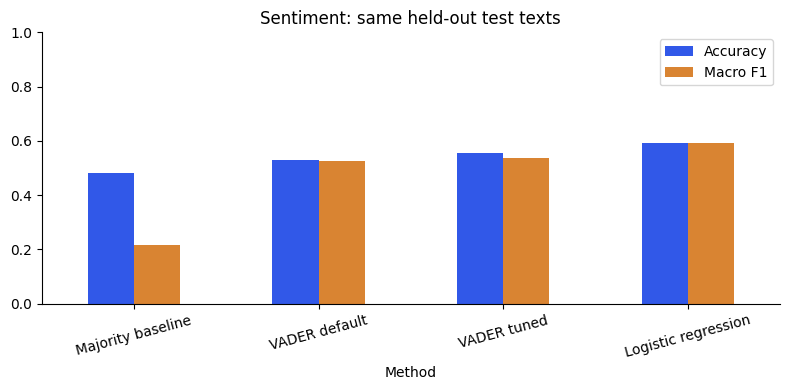

In [31]:
sentiment_predictions = {
    'Majority baseline': np.repeat(sent_train.label.mode().iloc[0], len(sent_test)),
    'VADER default': vader_predictions(sent_test.text),
    'VADER tuned': vader_predictions(sent_test.text, vader_threshold),
    'Logistic regression': sentiment_model.predict(sent_test.text)}
sentiment_results = pd.DataFrame([
    {'Method': name, 'Accuracy': accuracy_score(sent_test.label, prediction),
     'Macro F1': f1_score(sent_test.label, prediction, average='macro')}
    for name, prediction in sentiment_predictions.items()])
display(sentiment_results.round(3))
sentiment_results.set_index('Method')[['Accuracy', 'Macro F1']].plot.bar(
    color=[BLUE, ORANGE], ylim=(0, 1), rot=15, title='Sentiment: same held-out test texts')
plt.tight_layout()
plt.show()

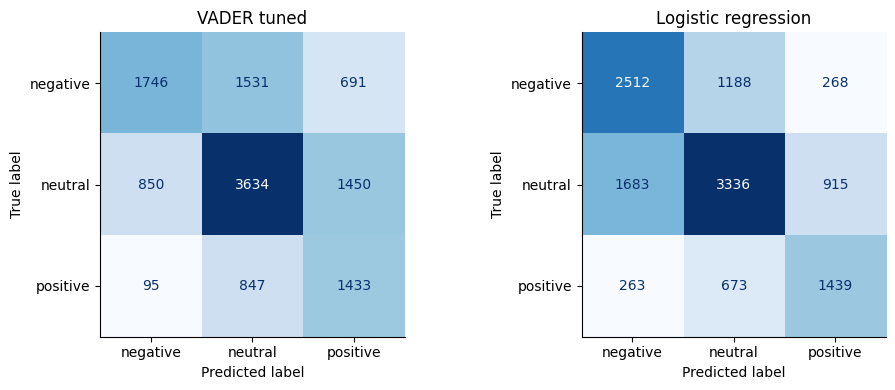

,precision,recall,f1-score,support
negative,0.563,0.633,0.596,3968.000
neutral,0.642,0.562,0.599,5934.000
positive,0.549,0.606,0.576,2375.000
accuracy,0.594,0.594,0.594,0.594
macro avg,0.585,0.600,0.591,12277.000
weighted avg,0.599,0.594,0.594,12277.000


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ['VADER tuned', 'Logistic regression']):
    matrix = confusion_matrix(sent_test.label, sentiment_predictions[name], labels=sentiment_labels)
    ConfusionMatrixDisplay(matrix, display_labels=sentiment_labels).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name)
fig.tight_layout()
plt.show()
chosen_predictions = sentiment_predictions[sentiment_choice]
display(pd.DataFrame(classification_report(sent_test.label, chosen_predictions,
                                           output_dict=True, zero_division=0)).T.round(3))

### What the sentiment results mean

Read the printed test table before making a claim about the winner. A macro F1 of 0.59 means there is still substantial error; it does not mean the model is 59% confident about every message. English-tweet performance is not evidence of performance on Kenyan student feedback. Sentiment stays separate from job ranking.

### 5.4 Check the skill rules and prepare a human review

These small checks catch common coding mistakes: aliases, technical punctuation and negation. They are **not** a measured skill-extraction accuracy. The review table leaves human labels blank; we do not copy the old notebook's hand marks onto different examples.

In [33]:
assert clean_text('C++ C# .NET node.js') == 'c++ c# .net node.js'
assert profile_skills('Python') == profile_skills('Python programming')
assert not profile_skills('I have no Python experience.')
assert not job_skills('Python and SQL are not required.')['required']
assert {labels[s] for s in job_skills('Requirements: Python and SQL are required.')['required']} == {'Python', 'SQL'}
assert {labels[s] for s in job_skills('Java preferred but not required.')['preferred']} == {'Java'}
assert not job_skills('About us: our website uses Python.')['required']
print('7 skill/preparation checks passed.')

review_pairs = []
for i, (_, cv_row) in enumerate(queries.head(5).iterrows()):
    for job_id in set(rankings['TF-IDF'][i]) | set(rankings['Semantic'][i]):
        review_pairs.append({'resume_id': cv_row.ID, 'job_id': jobs.iloc[job_id].job_id,
                             'job_title': jobs.iloc[job_id].title, 'relevant_0_or_1': ''})
review = pd.DataFrame(review_pairs).sample(frac=1, random_state=SEED)
review.to_csv(OUT / 'human_relevance_review.csv', index=False)
display(review.head(5))

7 skill/preparation checks passed.


,resume_id,job_id,job_title,relevant_0_or_1
37,18001081,3902874373,Elementary Teacher,
24,11616482,3905330537,7/8 Math Teacher at Propel East,
25,11616482,3901934866,Entry-Level Account Manager - Marketing,
36,18001081,3890889774,6th Grade Math Teacher - Middle School,
34,34303500,3904430434,Sales Development Manager - Entry Level,


## 6. Run the complete example

One function returns ranked jobs and the requirements the CV does not mention. A skill percentage means **coverage of detected required skills**, not a chance of employment. If no clear requirements were detected, the percentage is left blank. Expiry and eligibility are always shown.

In [34]:
def recommend(cv_text, top_k=5, method='TF-IDF', live_only=False):
    if not isinstance(cv_text, str) or not cv_text.strip(): raise ValueError('Enter CV text.')
    if isinstance(top_k, bool) or not isinstance(top_k, int) or not 1 <= top_k <= 20: raise ValueError('Choose 1–20 jobs.')
    if method not in ['TF-IDF', 'Semantic']: raise ValueError('Unknown matching method.')
    if job_tfidf.transform([prepare_resume(cv_text)]).nnz == 0: return []
    scores = lexical_scores(cv_text) if method == 'TF-IDF' else (embed([prepare_resume(cv_text)]) @ semantic_vectors.T).ravel()
    own_skills, result = profile_skills(cv_text), []
    for i in np.argsort(-scores, kind='stable'):
        if len(result) == top_k: break
        row = jobs.iloc[i]
        if scores[i] <= 0 or (live_only and (row.expired or row.eligibility != 'verified')): continue
        needs = job_skills(row.title + '\n' + row.description + '\n' + row.skills_desc)
        required = needs['required']
        result.append({'job_id': str(row.job_id), 'title': row.title, 'company': row.company_name,
                       'similarity': round(float(scores[i]), 3), 'location': row.location,
                       'required_coverage_pct': round(100 * len(own_skills & required) / len(required)) if required else None,
                       'required_not_mentioned': sorted(labels[s] for s in required - own_skills),
                       'preferred_not_mentioned': sorted(labels[s] for s in needs['preferred'] - own_skills),
                       'expired': bool(row.expired), 'eligibility': row.eligibility,
                       'application_url': row.application_url})
    return result

In [35]:
display(pd.DataFrame(recommend(sample_cv, top_k=3)))
print('Live verified jobs returned:', len(recommend(sample_cv, live_only=True)))
print('Auxiliary career guess:', fitted_career[career_choice].predict([prepare_resume(sample_cv)])[0])

def feedback_sentiment(text):
    if not text.strip(): raise ValueError('Enter feedback text.')
    if sentiment_choice == 'Logistic regression': return str(sentiment_model.predict([text])[0])
    return str(vader_predictions([text], vader_threshold)[0])

for message in ['The suggestions were helpful.', 'The page contains five jobs.', 'These results are disappointing.']:
    print(message, '→', feedback_sentiment(message))

,job_id,title,company,similarity,location,required_coverage_pct,required_not_mentioned,preferred_not_mentioned,expired,eligibility,application_url
0,3902785701,Developer,Tata Consultancy Services,0.271,"Boston, MA",67,[Java],[],True,unverified,https://ibegin.tcs.com/iBegin/jobs/308134J
1,3904951318,"SRE / Software Engineer (Kubernetes, AWS)",Dice,0.147,United States,50,[Java],[],True,unverified,https://click.appcast.io/track/j7vd0jg?cs=ivj&sjg=3073
2,3903471110,"Junior Python, SQL, AWS Developer","CALIBRE Systems, Inc.",0.121,"Alexandria, VA",22,"[Communication, Git, MySQL, PostgreSQL, approach challenges positi...","[C#, Java, JavaScript]",True,unverified,https://jobs.silkroad.com/CalibreSys/httpscalibresyscareerssilkroa...


Live verified jobs returned: 0
Auxiliary career guess: BANKING
The suggestions were helpful. → neutral
The page contains five jobs. → neutral
These results are disappointing. → negative


### What the example tells us

Inspect the actual job titles and missing skills, not just the scores. The auxiliary career guess can be wrong on a short student profile; it is deliberately not used in `recommend`. A Java role can still appear for someone who says they have no Java experience: text similarity is not a complete suitability decision, and the required-skills list must expose the gap. Historical jobs are demonstration records, not vacancies we promise are open.

## 7. Save the models and define the AI-service interface

This is the deployment stage of the data-mining process. Save the fitted models, lookup and job vectors together, then define the endpoints the group's backend can call. This is the **AI model service**, not Android's account/profile database backend. Everything is defined in this notebook; the saved files are outputs, not extra source-code dependencies.

In [36]:
saved_model = {
    'career_model': fitted_career[career_choice], 'job_tfidf': job_tfidf,
    'job_vectors': job_vectors, 'semantic_vectors': semantic_vectors, 'jobs': jobs,
    'skill_lookup': lookup, 'skill_labels': labels,
    'sentiment_model': sentiment_model, 'vader': vader,
    'sentiment_choice': sentiment_choice, 'vader_threshold': vader_threshold}
joblib.dump(saved_model, OUT / 'upshift_clear_models.joblib', compress=3)
encoder.save(str(OUT / 'semantic_encoder'))
career_results.to_csv(OUT / 'career_results.csv', index=False)
retrieval_results.to_csv(OUT / 'matching_category_check.csv', index=False)
sentiment_results.to_csv(OUT / 'sentiment_results.csv', index=False)
reloaded = joblib.load(OUT / 'upshift_clear_models.joblib')
assert np.array_equal(reloaded['sentiment_model'].predict(['Helpful and clear.']),
                      sentiment_model.predict(['Helpful and clear.']))
print('Models saved and reload checked:', OUT / 'upshift_clear_models.joblib')

Models saved and reload checked: C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\ai\clear_results\upshift_clear_models.joblib


### 7.1 The API routes

`/recommend` accepts CV text; `/sentiment` accepts feedback. A local token protects the POST routes during integration. It is not a production user-login system. The token is not printed or embedded in Android. Run this definition cell normally; it does not expose a public server.

In [37]:
import secrets
from fastapi import FastAPI, Header, HTTPException
from pydantic import BaseModel, Field

app = FastAPI(title='UpShift AI — academic prototype')
LOCAL_TOKEN = os.environ.get('UPSHIFT_API_TOKEN') or secrets.token_urlsafe(32)

class CVRequest(BaseModel):
    cv_text: str = Field(min_length=1, max_length=50000)
    top_k: int = Field(default=5, ge=1, le=20, strict=True)
    method: str = 'TF-IDF'

class FeedbackRequest(BaseModel):
    text: str = Field(min_length=1, max_length=10000)

def check_token(authorization):
    if not secrets.compare_digest(authorization.encode(), ('Bearer ' + LOCAL_TOKEN).encode()):
        raise HTTPException(401, 'Unauthorized')

In [38]:
@app.get('/health')
def health():
    return {'status': 'ok', 'jobs': len(jobs), 'catalogue': 'historical_research'}

@app.post('/recommend')
def recommend_route(request: CVRequest, authorization: str = Header(default='')):
    check_token(authorization)
    try: return {'matches': recommend(request.cv_text, request.top_k, request.method)}
    except ValueError as error: raise HTTPException(422, str(error)) from error

@app.post('/sentiment')
def sentiment_route(request: FeedbackRequest, authorization: str = Header(default='')):
    check_token(authorization)
    try: return {'label': feedback_sentiment(request.text), 'method': sentiment_choice}
    except ValueError as error: raise HTTPException(422, str(error)) from error

### 7.2 Check the interface without publishing it

These requests stay inside the notebook process. Check the health response, rejected unauthorised requests, a successful recommendation, feedback prediction and invalid input. The checks prove that the code connects; they do not measure prediction accuracy.

In [39]:
from fastapi.testclient import TestClient
client = TestClient(app)
headers = {'Authorization': 'Bearer ' + LOCAL_TOKEN}
assert client.get('/health').status_code == 200
assert client.post('/recommend', json={'cv_text': sample_cv}).status_code == 401
response = client.post('/recommend', headers=headers, json={'cv_text': sample_cv, 'top_k': 3})
assert response.status_code == 200 and len(response.json()['matches']) == 3
assert client.post('/sentiment', headers=headers, json={'text': 'Helpful and clear.'}).status_code == 200
assert client.post('/recommend', headers=headers, json={'cv_text': ' '}).status_code == 422
assert client.post('/recommend', headers=headers, json={'cv_text': sample_cv, 'top_k': True}).status_code == 422
print('6 interface checks passed. No public service was started.')

6 interface checks passed. No public service was started.


### 7.3 Optional local integration server

Leave the switch off for normal Run All. To test from a backend on the same computer, set `UPSHIFT_API_TOKEN` before the API cells and enable the switch below. Android/backend integration and public deployment still need appropriate networking and user authentication. A hosted Colab runtime is not your PC's localhost.

In [40]:
START_LOCAL_SERVICE = False
if START_LOCAL_SERVICE:
    import threading, uvicorn
    server_thread = threading.Thread(target=uvicorn.run,
        kwargs={'app': app, 'host': '127.0.0.1', 'port': 8000}, daemon=True)
    server_thread.start()

## 8. Conclusion and limits

- **Main feature:** rank jobs from CV text, then explain required and preferred skills not mentioned.
- **Separate experiment:** compare VADER and logistic regression for sentiment using the same labelled test tweets.
- **Evidence:** cleaning counts, EDA plots, training-only model selection, held-out results and interface checks are above.
- **Not established:** true CV–job relevance accuracy, Kenyan eligibility, live vacancy availability or performance on Kenyan student feedback. The human-review file is provided for future relevance labels.
- **Known limits:** ESCO phrase rules can miss context; long texts are sampled for semantic matching; a short student CV can confuse the career classifier.

All stages and the service interface are in this notebook. The larger engineering handoff can be used later for deployment, but it is not required to run these cells.

### Sources

Project-provided Resume.csv, postings.csv and ESCO skills_en.csv; retain their original dataset terms. Sentiment data: [TweetEval](https://github.com/cardiffnlp/tweeteval), exact revision shown above. Dictionary baseline: [NLTK VADER](https://www.nltk.org/api/nltk.sentiment.vader.html). Pretrained meaning model: [MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), pinned revision, Apache-2.0. Training and evaluation: [scikit-learn](https://scikit-learn.org/stable/).